# US Meta political and issue ad spend, late 2025 to early 2026

**Sonya Baigildin** · [github.com/SonyaBai](https://github.com/SonyaBai)

This notebook reads the aggregates in `data/processed/` and walks the same questions as the README. It does not reload the raw CSVs. `python analysis.py` is what rebuilds those aggregates from `data/raw/`.

The subject is Meta ads about social issues, elections, or politics in the United States. The weekly file is 23 Monday–Sunday reports from 20 October 2025 through 19 April 2026. The weeks of 10, 17, and 24 November 2025 are not in the file. The lifelong file is a separate snapshot through 25 October 2025.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from src.formatters import per_ad, per_person, pretty_category, rate_pct, usd

ROOT = Path.cwd()
PROCESSED = ROOT / "data" / "processed"
IMAGES = ROOT / "images"

weekly = pd.read_csv(PROCESSED / "weekly_spend.csv")
advertisers = pd.read_csv(
    PROCESSED / "advertisers.csv",
    dtype={"page_id": "string", "page_name": "string", "disclaimer": "string", "category": "string"},
)
states = pd.read_csv(PROCESSED / "states.csv")
lifelong = pd.read_csv(PROCESSED / "lifelong_top.csv")
coverage = pd.read_csv(PROCESSED / "coverage.csv", dtype=str).set_index("key")["value"]

def cov(key):
    return int(coverage.loc[key])

total = int(weekly["spend_usd"].sum())
assert total == cov("advertiser_spend_weekly")
print("Observed weekly spend", usd(total))
print("Lifelong spend through 25 Oct 2025", usd(cov("advertiser_spend_lifelong")))
print("Observed weeks", cov("n_weeks"))
print("Location report", usd(cov("location_spend_weekly")))
print("Region file", usd(cov("region_spend_weekly")))
print("Location minus advertisers", usd(cov("location_spend_weekly") - total))
print("Location minus regions", usd(cov("location_spend_weekly") - cov("region_spend_weekly")))

Observed weekly spend $300,611,319
Lifelong spend through 25 Oct 2025 $5,347,140,271
Observed weeks 23
Location report $301,341,236
Region file $276,382,659
Location minus advertisers $729,917
Location minus regions $24,958,577


## 1. Weekly spend

Missing weeks stay missing. They are not zeros, and they are not interpolated. The period total is the sum of the weeks that were published.

Highest 2025-10-27 $19,514,436
Lowest 2026-01-05 $9,435,639
Post-snapshot spend $285,281,823
Overlap week of 20 Oct 2025 $15,329,496


,date_start,date_end,spend,num_ads,advertiser_rows
0,2025-10-20,2025-10-26,"$15,329,496",209679,8242
1,2025-10-27,2025-11-02,"$19,514,436",196877,9131
2,2025-11-03,2025-11-09,"$13,088,002",179904,8692
3,2025-12-01,2025-12-07,"$12,722,285",196745,5506
4,2025-12-08,2025-12-14,"$11,383,446",135931,5327
5,2025-12-15,2025-12-21,"$11,160,167",190214,5273
6,2025-12-22,2025-12-28,"$11,001,279",140416,4758
7,2025-12-29,2026-01-04,"$10,306,159",169524,4743
8,2026-01-05,2026-01-11,"$9,435,639",145083,4885
9,2026-01-12,2026-01-18,"$11,376,881",175246,5462


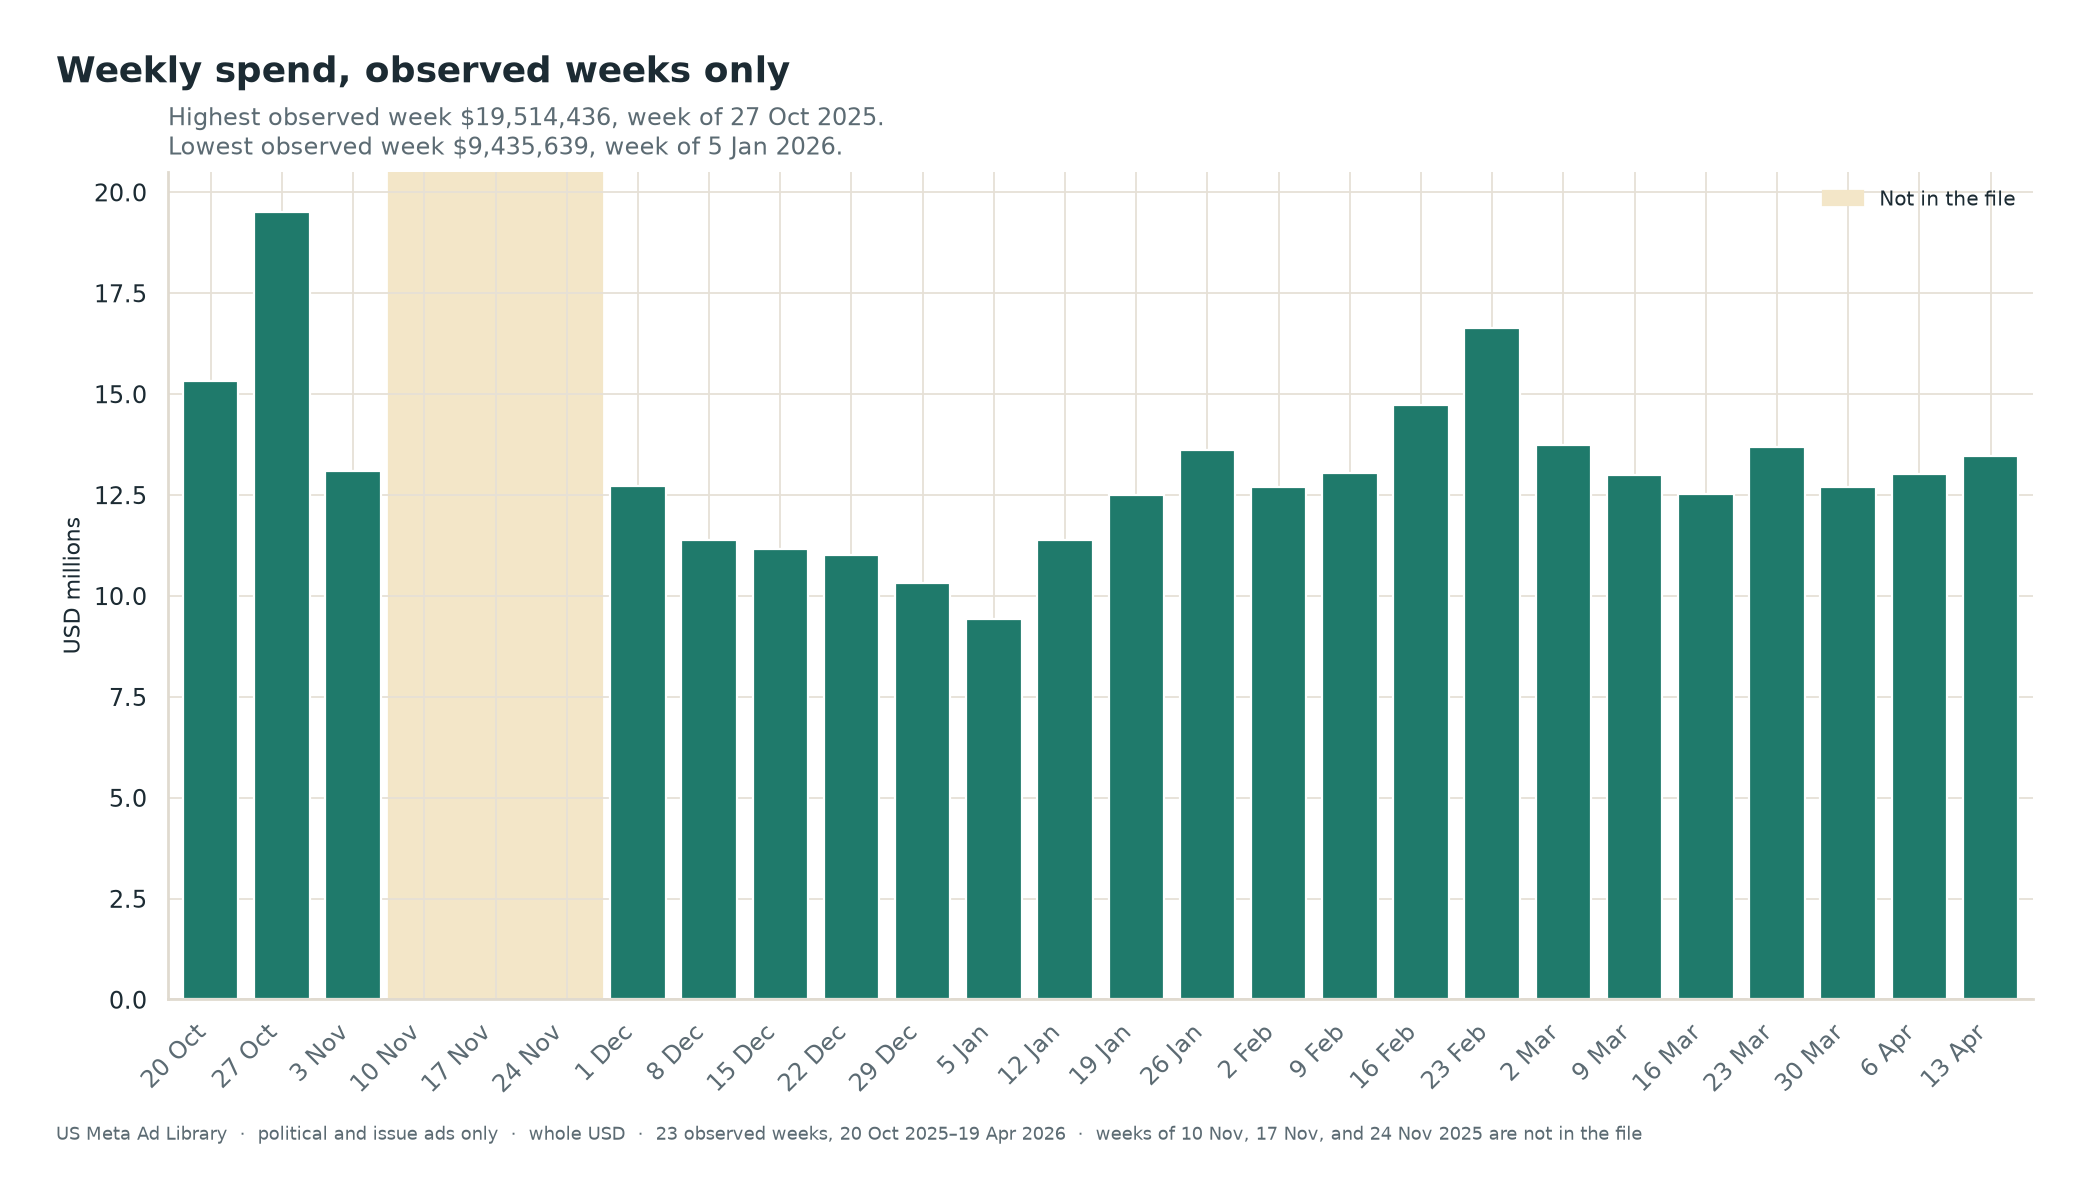

In [2]:
show = weekly[["date_start", "date_end", "spend_usd", "num_ads", "advertiser_rows"]].copy()
show["spend"] = show["spend_usd"].map(usd)
peak = weekly.loc[weekly["spend_usd"].idxmax()]
trough = weekly.loc[weekly["spend_usd"].idxmin()]
print("Highest", peak.date_start, usd(int(peak.spend_usd)))
print("Lowest", trough.date_start, usd(int(trough.spend_usd)))
print("Post-snapshot spend", usd(cov("post_snapshot_spend")))
print("Overlap week of 20 Oct 2025", usd(cov("overlap_week_spend")))
display(show[["date_start", "date_end", "spend", "num_ads", "advertiser_rows"]])
display(Image(filename=str(IMAGES / "weekly_spend.png")))

The high is the week of 27 October 2025, at $19,514,436. The low is the week of 5 January 2026, at $9,435,639. Spend steps down across the five observed weeks from 1 December through 29 December, then rises to $16,624,793 in the week of 23 February 2026. From 2 March through 13 April, every observed week is between $12,512,024 and $13,740,856.

## 2. Advertisers and concentration

An advertiser is a page id plus the exact disclaimer string. Positive means the observed weekly sum is above zero.

Positive advertisers 15,028
Top 10 $32,293,328 10.74%
Top 1% (151) $146,954,072 48.89%
Advertisers to 50% 161
Advertisers to 80% 1,004
Median $1,441
Mean $20,003.41


,advertiser,category_label,spend,lifelong,weeks_observed
0,prageru,Unclassified,"$4,783,287","$34,125,203",23
1,james talarico (talarico for texas),Candidate or officeholder,"$4,502,909",$0,17
2,democrats (dnc services corp./dem. nat'l commi...,Party,"$4,059,837","$24,439,798",23
3,end the wokeness,Unclassified,"$3,739,557","$6,645,893",23
4,kalshi - trade the headlines (kalshi inc.),Company,"$3,059,787","$5,685,645",17
5,jon ossoff (jon ossoff for senate),Candidate or officeholder,"$2,797,795","$9,105,970",23
6,progressive turnout project,Advocacy,"$2,590,820","$22,664,752",23
7,doctors without borders/médecins sans frontièr...,Advocacy,"$2,377,451","$6,438,476",23
8,captain mark kelly (mark kelly for senate),Candidate or officeholder,"$2,290,055","$13,459,364",23
9,military assistance,Unclassified,"$2,091,830","$495,672",22


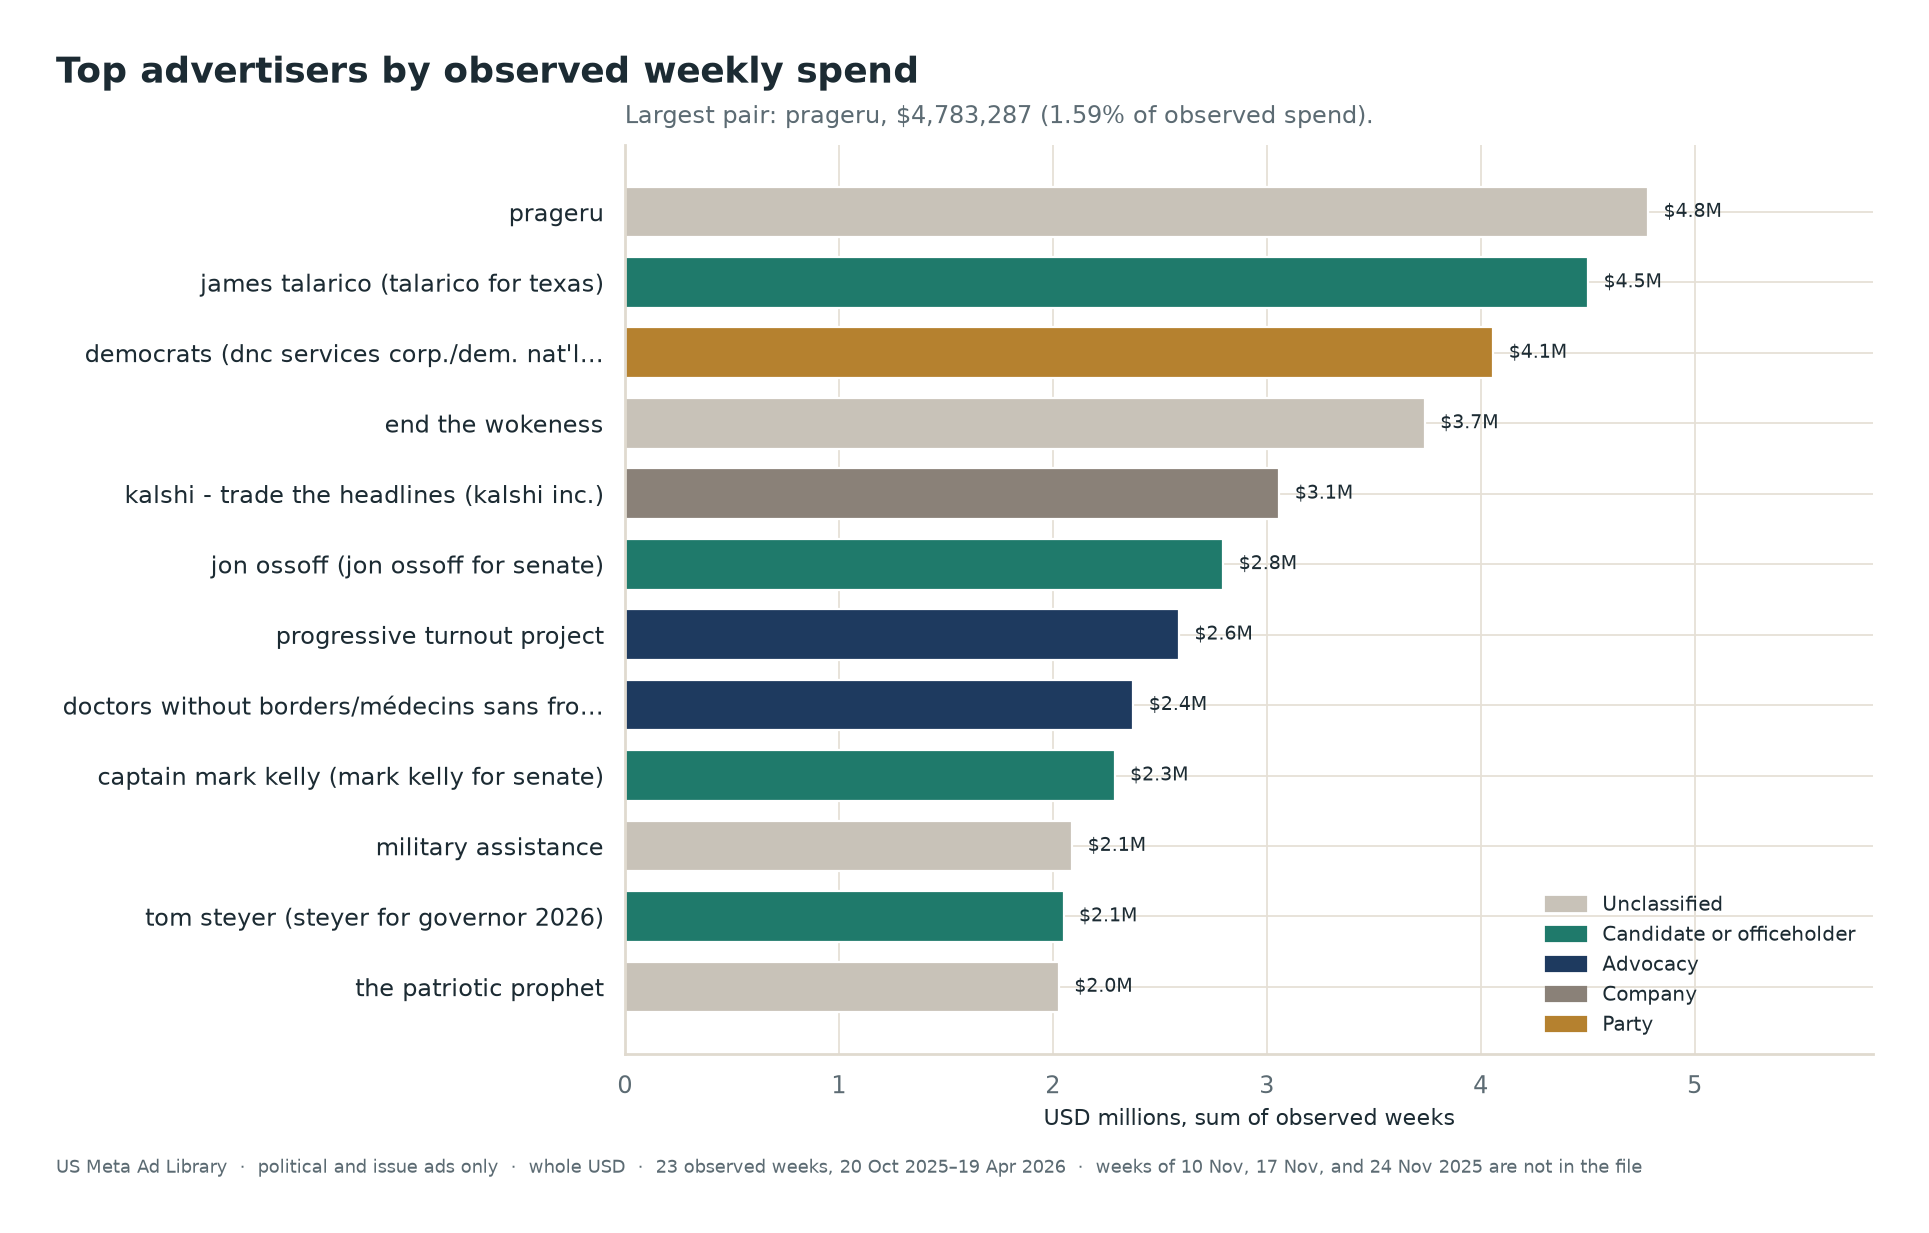

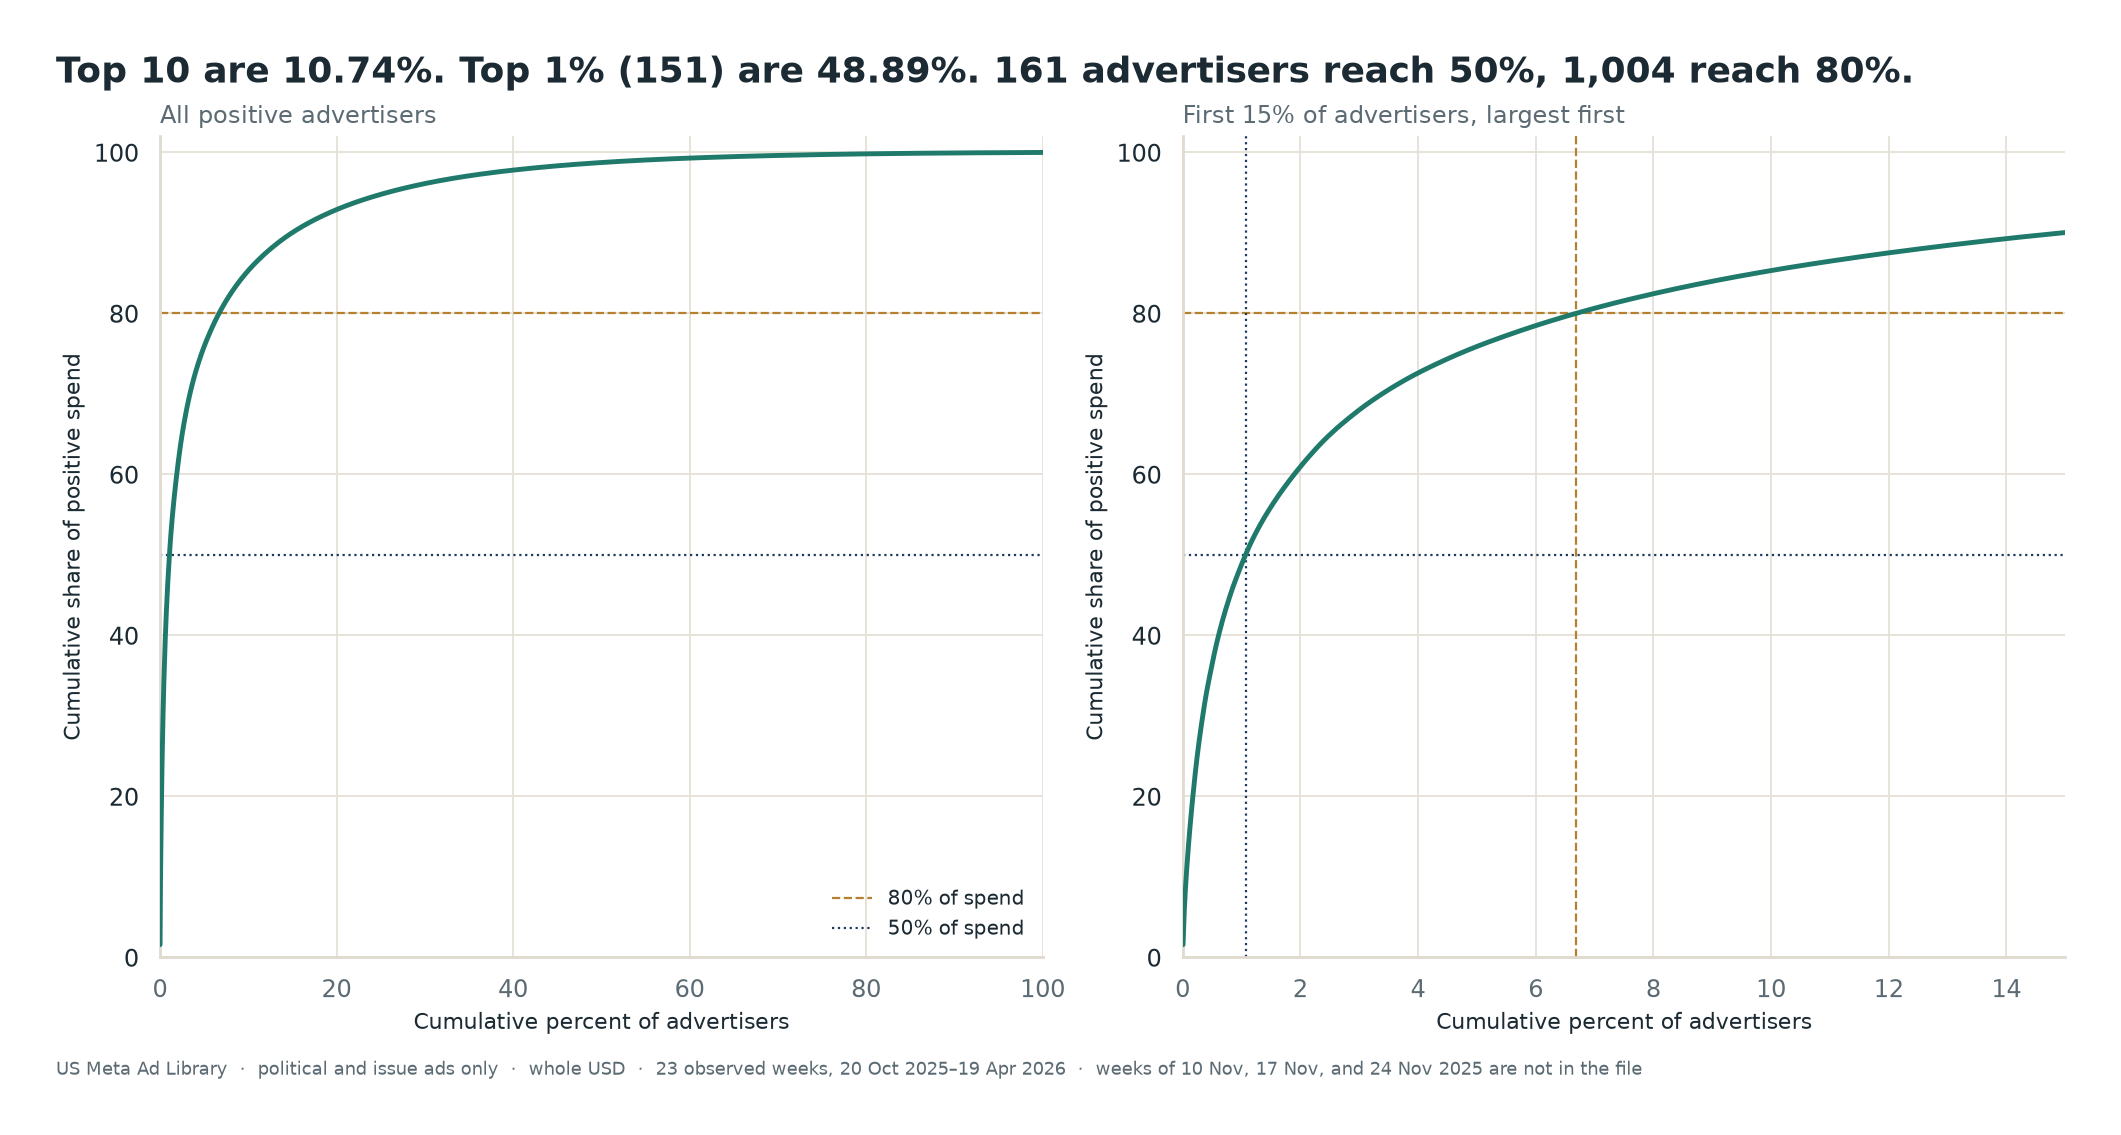

In [3]:
positive = advertisers.loc[advertisers["spend_usd"] > 0].sort_values(
    ["spend_usd", "page_id", "disclaimer"], ascending=[False, True, True]
)
n = len(positive)
top10 = int(positive.head(10)["spend_usd"].sum())
top1_n = (n + 99) // 100
top1 = int(positive.head(top1_n)["spend_usd"].sum())
ordered = positive.reset_index(drop=True)
cumulative = ordered["spend_usd"].cumsum()
n50 = int(ordered.index[(cumulative * 2) >= total][0]) + 1
n80 = int(ordered.index[(cumulative * 5) >= total * 4][0]) + 1
print(f"Positive advertisers {n:,}")
print(f"Top 10 {usd(top10)} {rate_pct(top10, total)}")
print(f"Top 1% ({top1_n:,}) {usd(top1)} {rate_pct(top1, total)}")
print(f"Advertisers to 50% {n50:,}")
print(f"Advertisers to 80% {n80:,}")
spends = ordered["spend_usd"].tolist()
mid = len(spends) // 2
median = spends[mid] if len(spends) % 2 else (spends[mid - 1] + spends[mid]) / 2
print("Median", f"${median:,.2f}" if not float(median).is_integer() else usd(int(median)))
print("Mean", per_ad(total, n))

def label(row):
    page = str(row.page_name)
    disc = str(row.disclaimer)
    if disc and disc != page and disc != "these ads ran without a disclaimer":
        return f"{page} ({disc})"
    return page

top = ordered.head(12).copy()
top["advertiser"] = [label(row) for row in top.itertuples()]
top["spend"] = top["spend_usd"].map(usd)
top["lifelong"] = top["lifelong_spend_usd"].map(usd)
top["category_label"] = top["category"].map(pretty_category)
display(top[["advertiser", "category_label", "spend", "lifelong", "weeks_observed"]])
display(Image(filename=str(IMAGES / "top_advertisers.png")))
display(Image(filename=str(IMAGES / "pareto.png")))

The top 10 are 10.74% of observed spend. The top 1%, 151 advertisers, are 48.89%. Half the positive dollars are 161 advertisers, and 80% are 1,004. The median positive advertiser is $1,441 and the mean is $20,003.41. prageru is the largest single pair, at $4,783,287.

`talarico for texas` is $0 lifelong under that disclaimer. The page is not new: it also ran as `james talarico campaign`. The same is true of `steyer for governor 2026` on a page whose lifelong spend includes `tom steyer 2020`.

## 3. States

State dollars are the location report. Per resident uses the Census Vintage 2025 resident population on 1 July 2025.

,location_name,spend,share,per_resident
0,california,"$34,010,698",11.29%,$0.86
1,texas,"$27,172,150",9.02%,$0.86
2,new york,"$18,878,870",6.26%,$0.94
3,florida,"$18,175,183",6.03%,$0.77
4,virginia,"$12,835,661",4.26%,$1.45
5,illinois,"$12,245,495",4.06%,$0.96
6,pennsylvania,"$11,358,744",3.77%,$0.87
7,georgia,"$9,903,919",3.29%,$0.88
8,michigan,"$9,523,755",3.16%,$0.94
9,north carolina,"$9,311,219",3.09%,$0.83


,census_name,per_resident,spend
35,District of Columbia,$3.19,"$2,215,004"
31,Maine,$1.81,"$2,559,622"
42,Alaska,$1.67,"$1,231,269"
4,Virginia,$1.45,"$12,835,661"
25,Iowa,$1.18,"$3,828,526"
48,Wyoming,$1.16,"$684,372"
12,Colorado,$1.15,"$6,888,631"
45,South Dakota,$1.10,"$1,033,133"


California, Texas, New York, Florida 32.60%


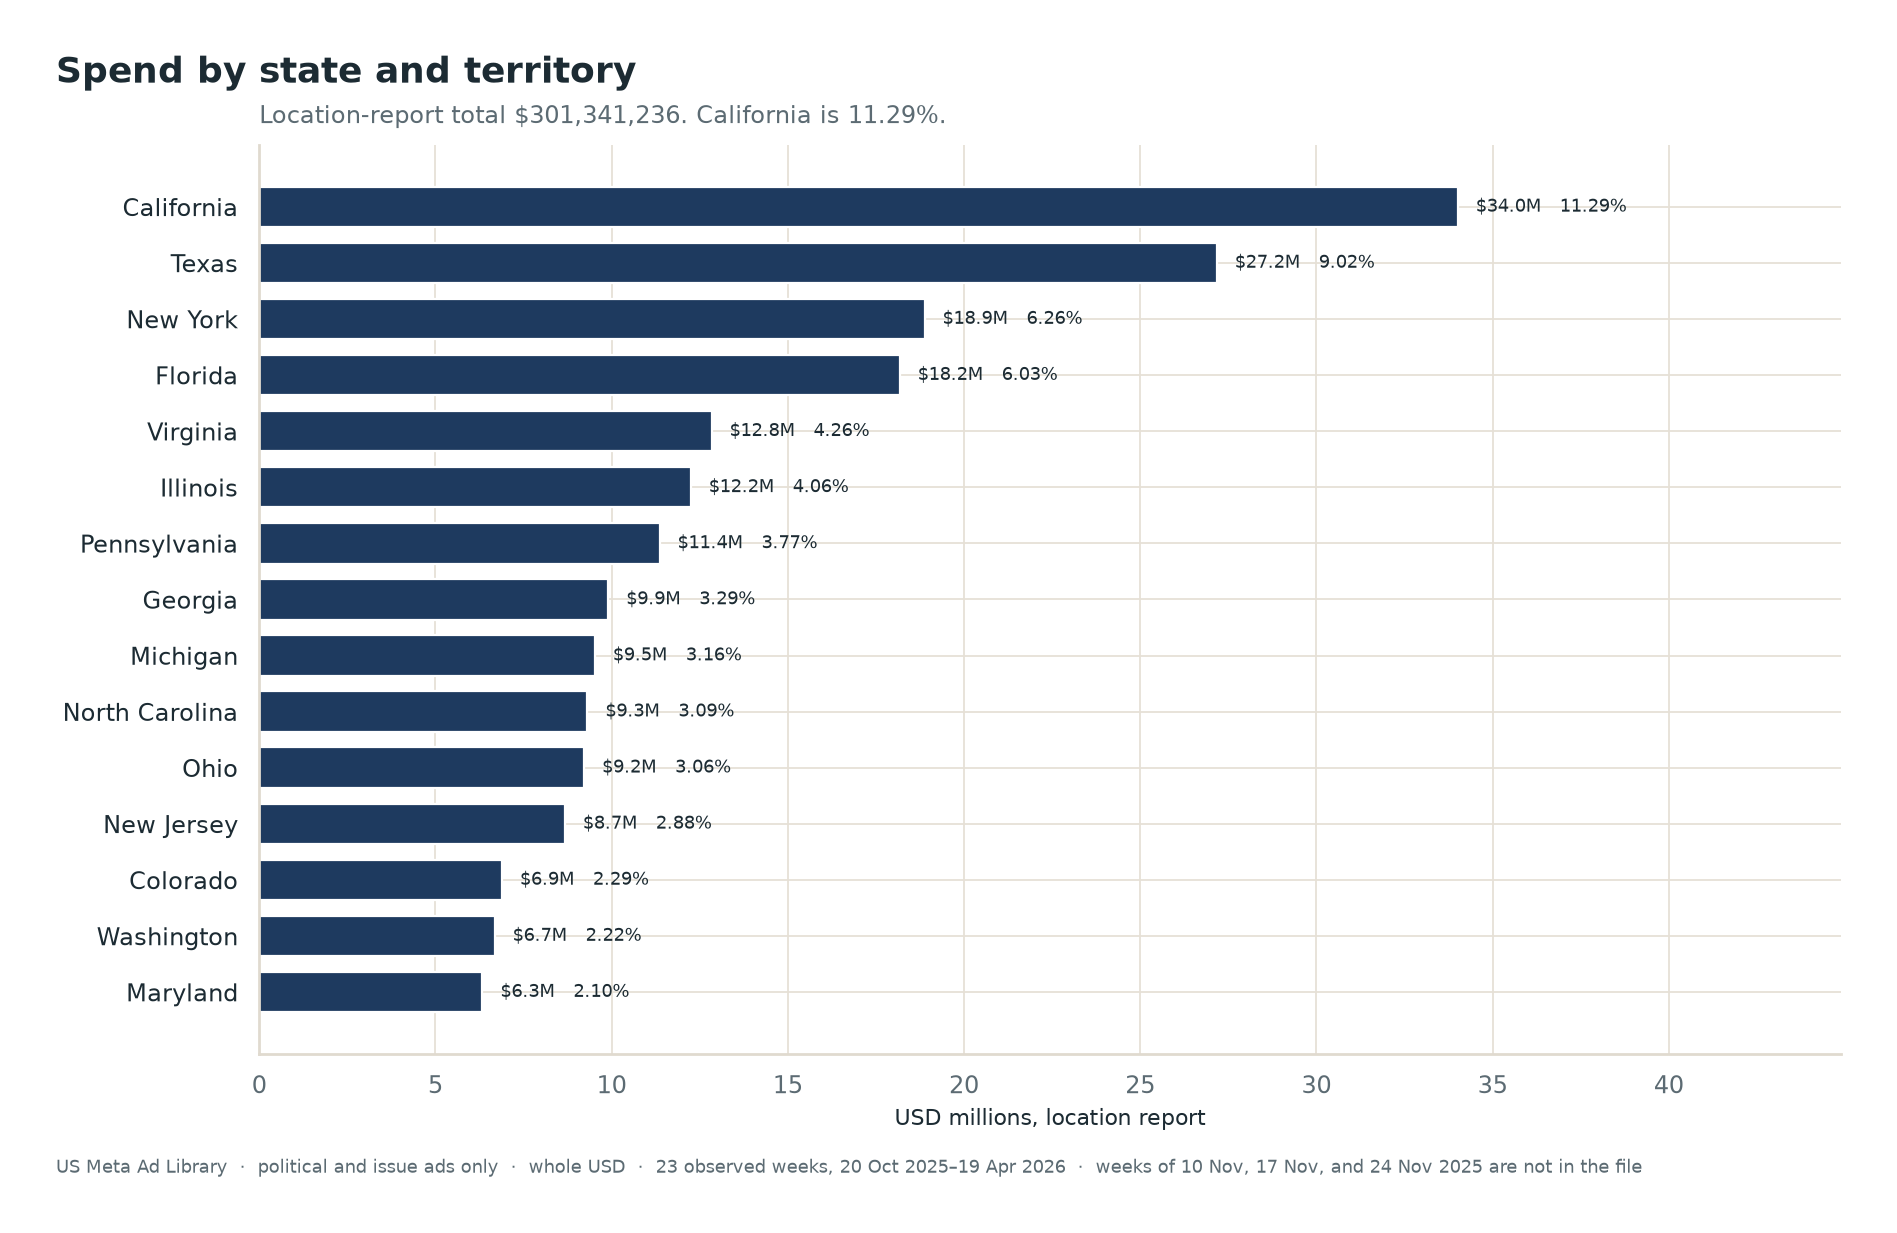

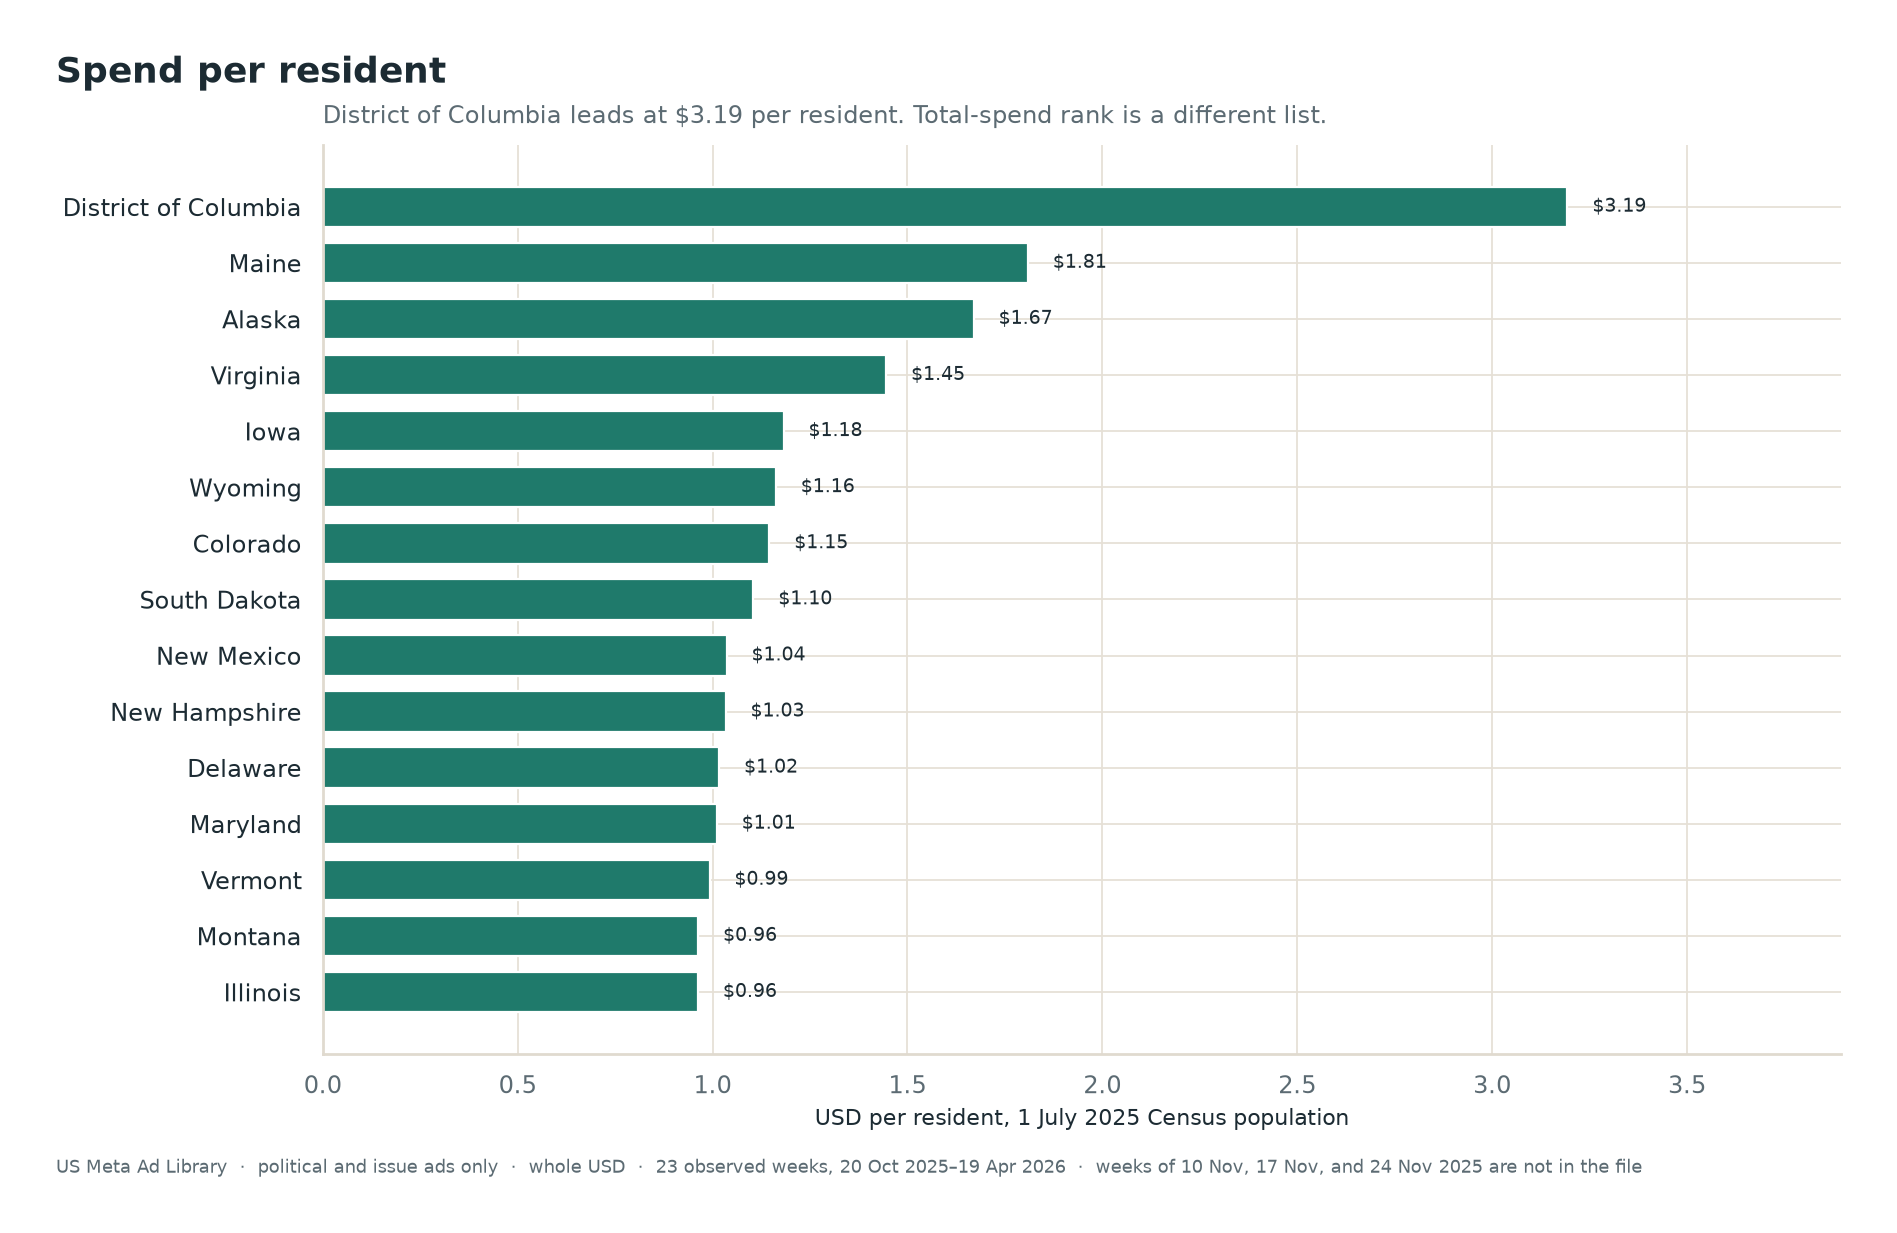

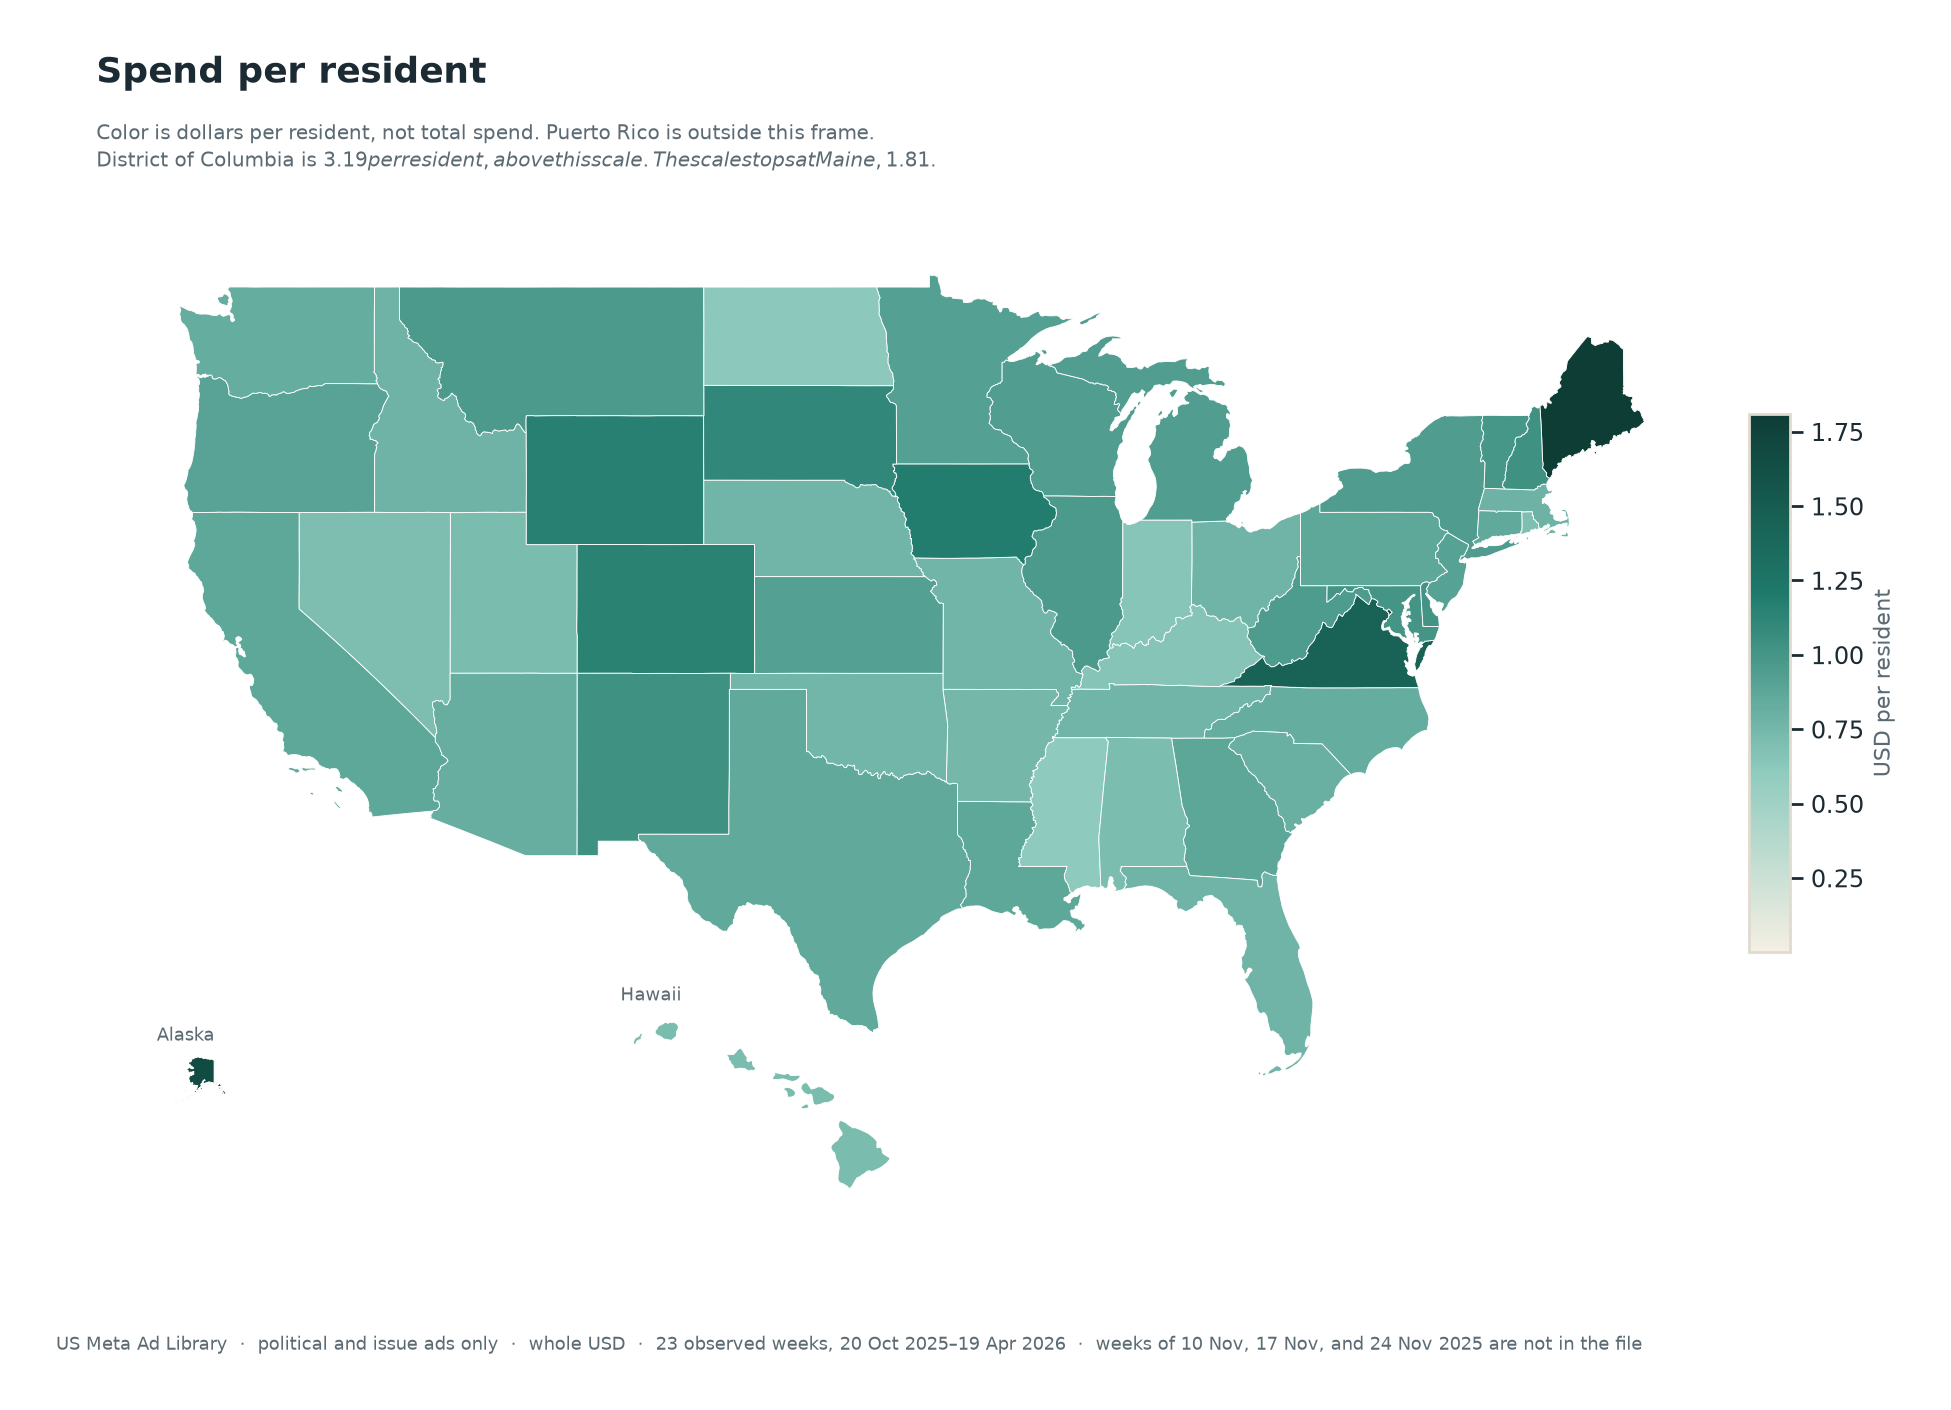

In [4]:
location_total = int(states["spend_usd"].sum())
assert location_total == cov("location_spend_weekly")
ranked = states.sort_values("spend_usd", ascending=False)
top_states = ranked.head(12).copy()
top_states["spend"] = top_states["spend_usd"].map(usd)
top_states["share"] = [rate_pct(int(value), location_total) for value in top_states["spend_usd"]]
top_states["per_resident"] = [
    "n/a" if pd.isna(pop) else per_person(int(spend), int(pop))
    for spend, pop in zip(top_states["spend_usd"], top_states["population_2025"])
]
display(top_states[["location_name", "spend", "share", "per_resident"]])
per_capita = states.dropna(subset=["population_2025"]).sort_values("per_capita", ascending=False)
leaders = per_capita.head(8).copy()
leaders["per_resident"] = [
    per_person(int(spend), int(pop))
    for spend, pop in zip(leaders["spend_usd"], leaders["population_2025"])
]
leaders["spend"] = leaders["spend_usd"].map(usd)
display(leaders[["census_name", "per_resident", "spend"]])
four = int(ranked.head(4)["spend_usd"].sum())
print("California, Texas, New York, Florida", rate_pct(four, location_total))
display(Image(filename=str(IMAGES / "state_spend.png")))
display(Image(filename=str(IMAGES / "state_per_capita.png")))
display(Image(filename=str(IMAGES / "state_choropleth.png")))

California is $34,010,698, 11.29% of the location report. California and Texas are both $0.86 per resident. The District of Columbia is $3.19 per resident on $2,215,004. The map is per resident, and the District of Columbia sits above the color scale.

## 4. Categories

The labels are keyword rules on the page name and the disclaimer (`src/classify.py`). Unclassified means no rule matched. It is the largest spend bucket, which is a limit of the rules.

,category_label,spend,share,positive
5,Unclassified,"$116,835,684",38.87%,6827
0,Advocacy,"$73,213,037",24.35%,2053
1,Candidate or officeholder,"$54,409,681",18.10%,4233
2,Company,"$32,774,688",10.90%,767
6,Party,"$8,995,005",2.99%,301
4,Media,"$8,787,340",2.92%,305
3,Government,"$5,595,884",1.86%,542


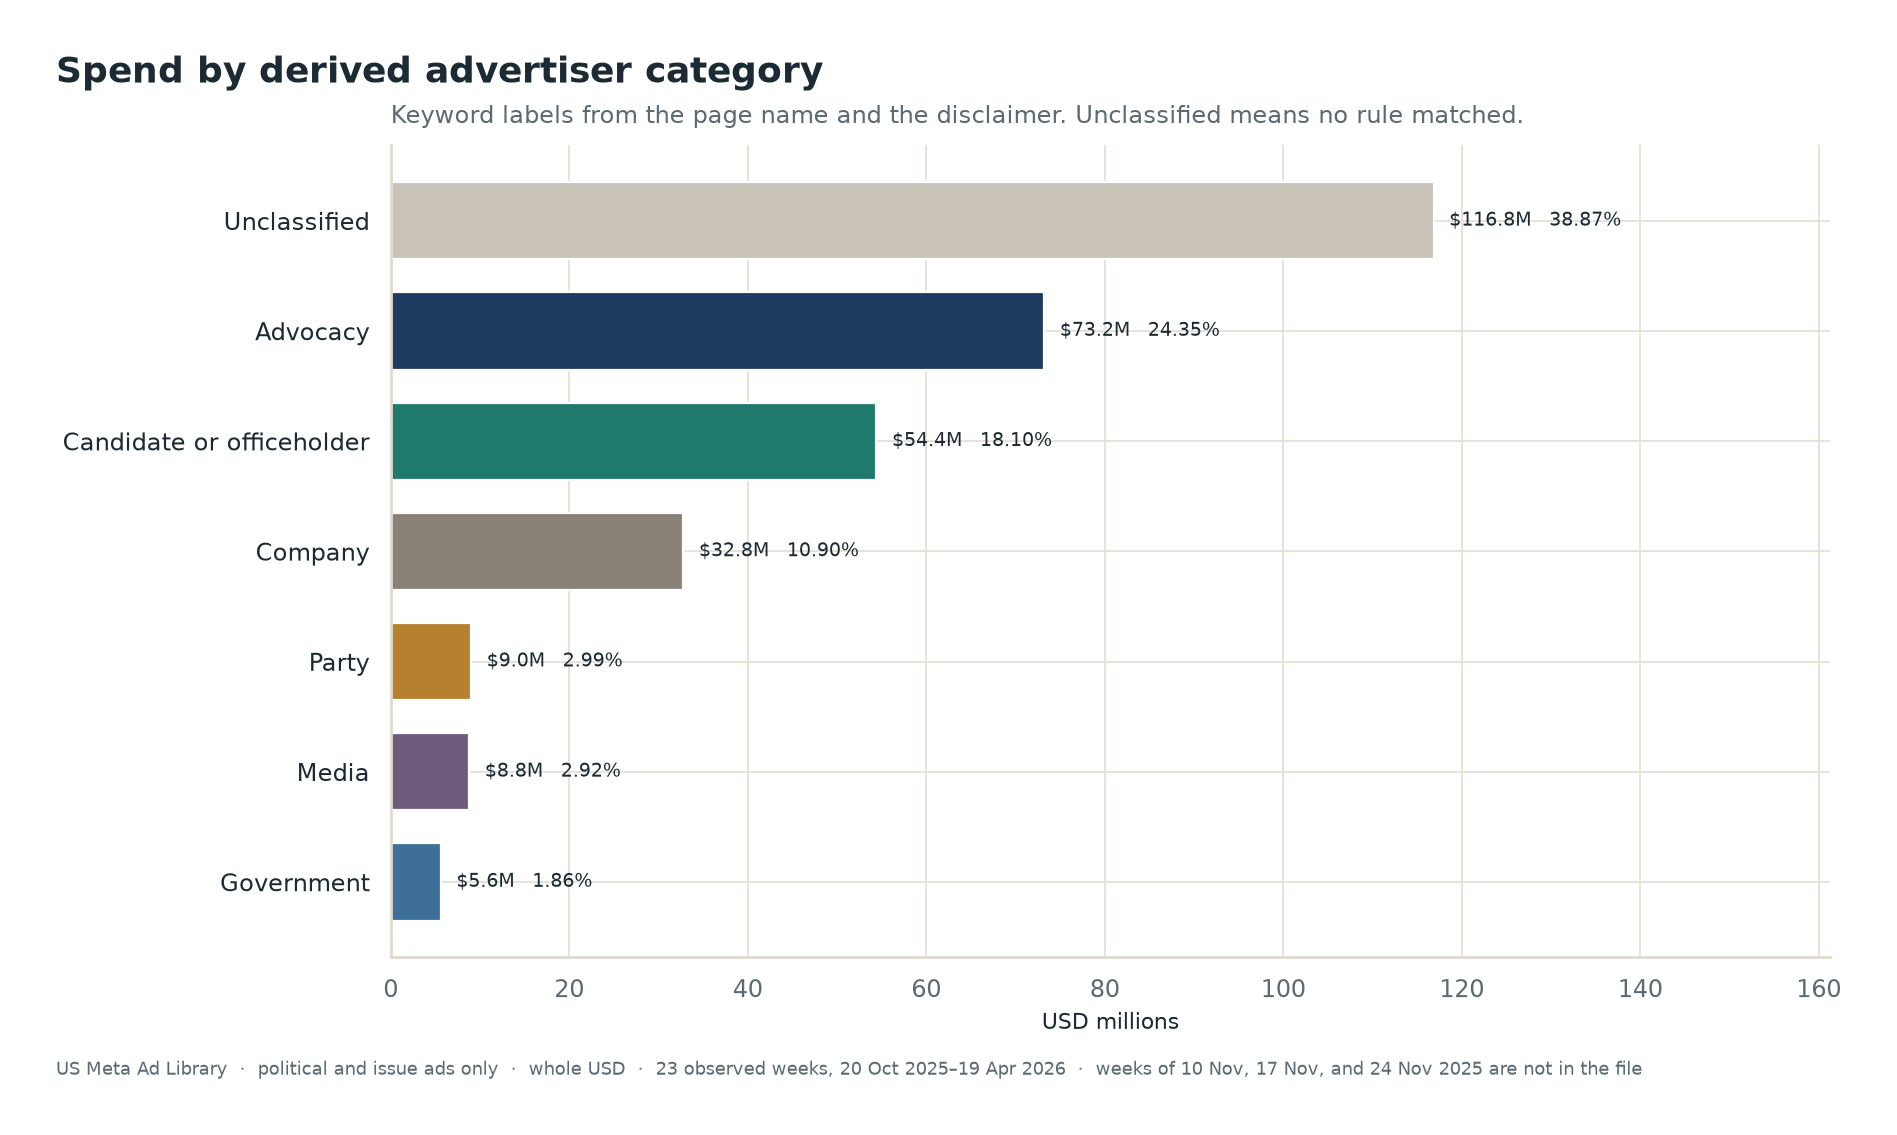

In [5]:
categories = (
    advertisers.groupby("category", as_index=False)
    .agg(spend_usd=("spend_usd", "sum"), positive=("spend_usd", lambda s: int((s > 0).sum())))
    .sort_values("spend_usd", ascending=False)
)
categories["category_label"] = categories["category"].map(pretty_category)
categories["spend"] = categories["spend_usd"].map(lambda value: usd(int(value)))
categories["share"] = [rate_pct(int(value), total) for value in categories["spend_usd"]]
display(categories[["category_label", "spend", "share", "positive"]])
display(Image(filename=str(IMAGES / "categories.png")))

## 5. Spend per ad-week, and large versus small

`num_ads` summed across weeks is ad-weeks, not distinct ads. No weekly row in the raw file has a positive amount below $101. Rows at $0 are left at $0.

Ad-weeks 3,538,542
Spend per ad-week $84.95
Spend per ad-week on positive rows $90.40
Rows at $0 73,604 of 154,301 holding 6.03% of ad-weeks


,bucket,advertisers,advertiser_share,spend,spend_share,per_ad_week
0,$0,"24,035",61.53%,$0,0.00%,$0.00
1,$1–$99,0,0.00%,$0,0.00%,n/a
2,$100–$999,"6,534",16.73%,"$2,582,823",0.86%,$22.06
3,"$1,000–$9,999","5,656",14.48%,"$20,377,265",6.78%,$20.84
4,"$10,000–$99,999","2,350",6.02%,"$69,270,786",23.04%,$42.21
5,"$100,000–$999,999",441,1.13%,"$122,332,217",40.69%,$221.56
6,"$1,000,000 or more",47,0.12%,"$86,048,228",28.62%,$554.51


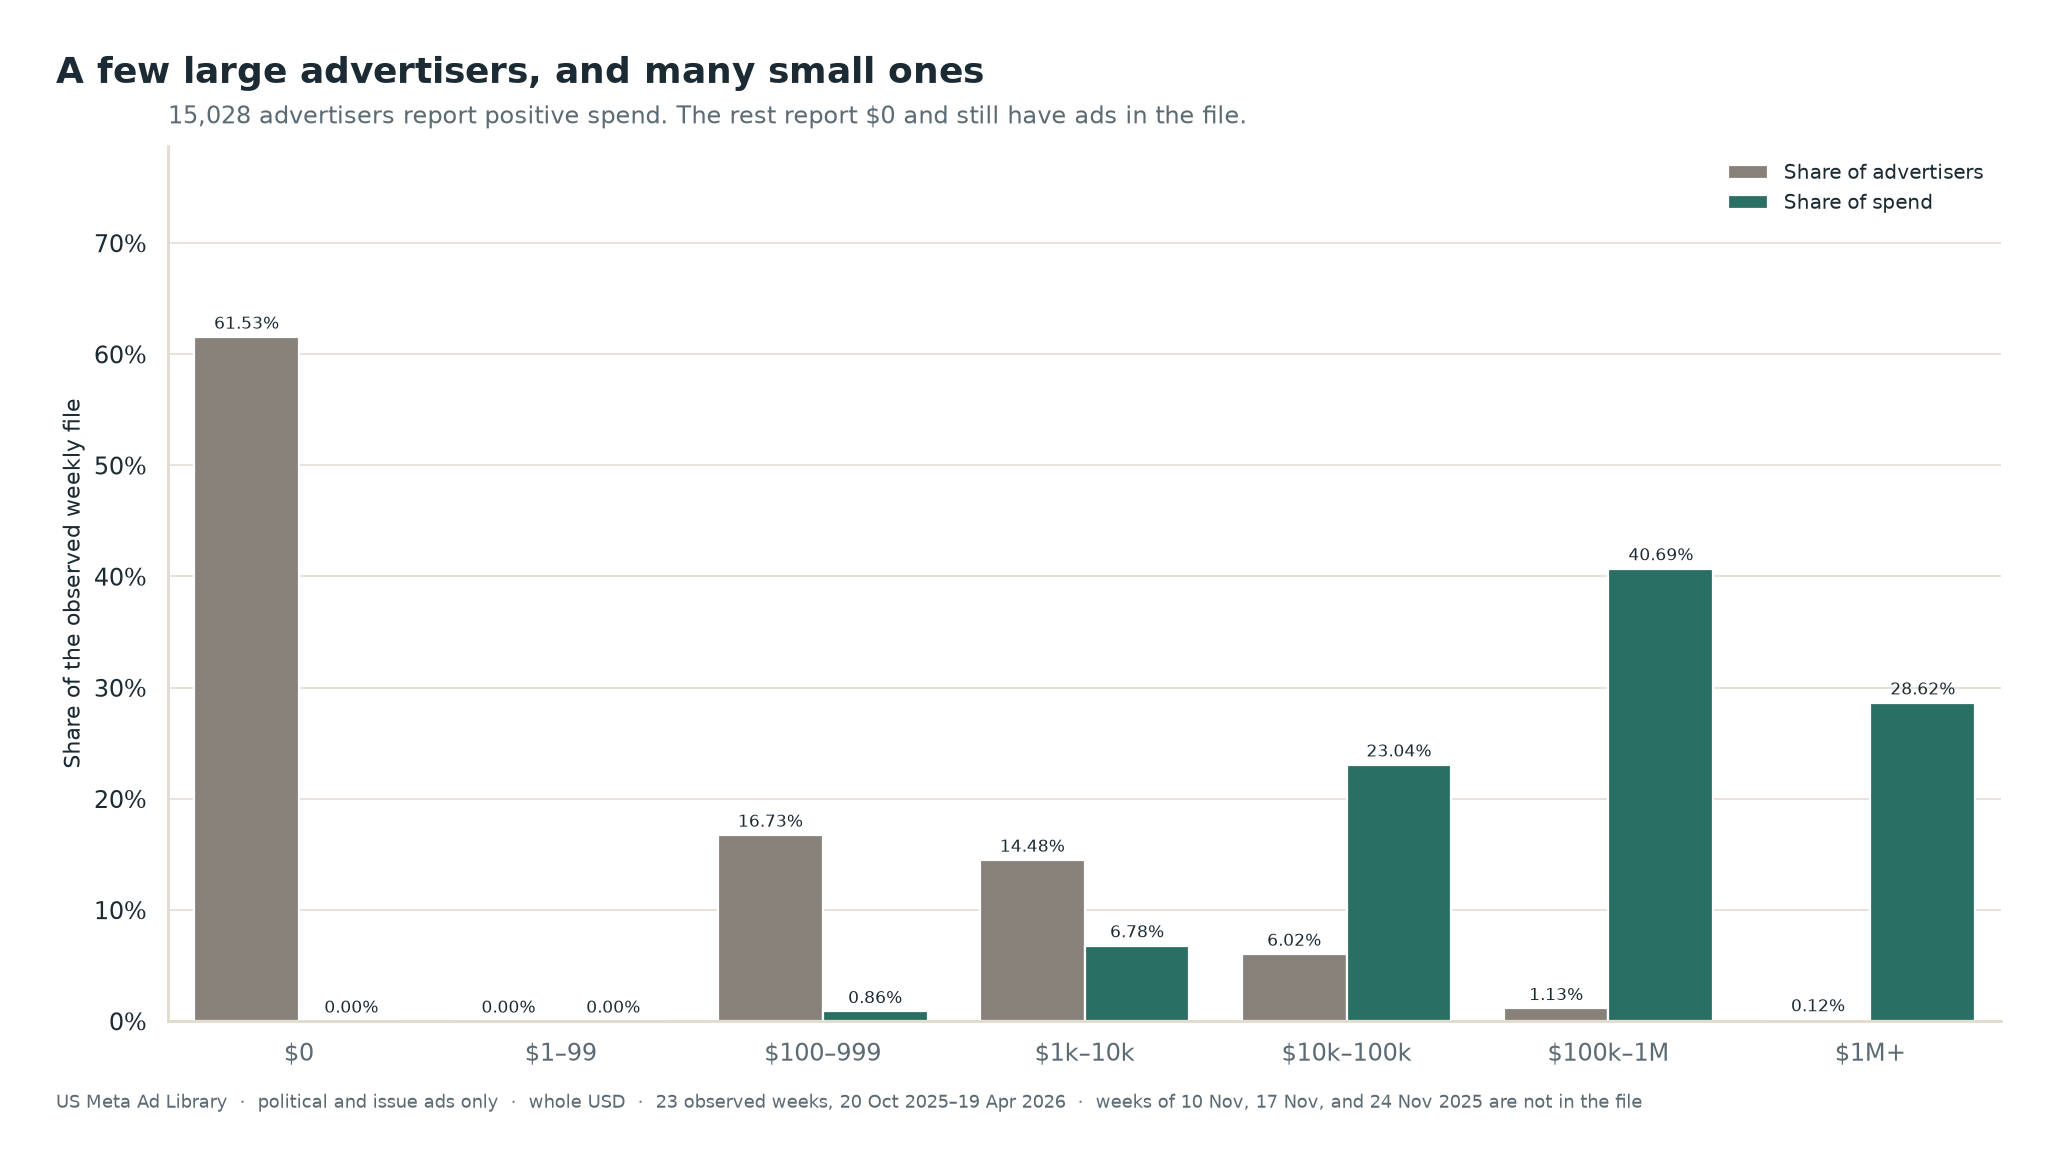

In [6]:
print("Ad-weeks", f"{cov('num_ads_weekly'):,}")
print("Spend per ad-week", per_ad(total, cov("num_ads_weekly")))
print("Spend per ad-week on positive rows", per_ad(cov("positive_row_spend"), cov("positive_row_ads")))
print(
    "Rows at $0",
    f"{cov('zero_rows_weekly'):,} of {cov('advertiser_rows_weekly'):,}",
    "holding",
    rate_pct(cov("zero_row_ads"), cov("num_ads_weekly")),
    "of ad-weeks",
)
bins = [
    ("$0", 0, 1),
    ("$1–$99", 1, 100),
    ("$100–$999", 100, 1_000),
    ("$1,000–$9,999", 1_000, 10_000),
    ("$10,000–$99,999", 10_000, 100_000),
    ("$100,000–$999,999", 100_000, 1_000_000),
    ("$1,000,000 or more", 1_000_000, None),
]
rows = []
n_pairs = len(advertisers)
for bucket, low, high in bins:
    if high is None:
        part = advertisers.loc[advertisers["spend_usd"] >= low]
    else:
        part = advertisers.loc[(advertisers["spend_usd"] >= low) & (advertisers["spend_usd"] < high)]
    spend = int(part["spend_usd"].sum())
    ads = int(part["num_ads"].sum())
    rows.append(
        {
            "bucket": bucket,
            "advertisers": f"{len(part):,}",
            "advertiser_share": rate_pct(len(part), n_pairs),
            "spend": usd(spend),
            "spend_share": rate_pct(spend, total),
            "per_ad_week": per_ad(spend, ads),
        }
    )
display(pd.DataFrame(rows))
display(Image(filename=str(IMAGES / "advertiser_size.png")))

24,035 pairs are at $0, 61.53% of pairs and none of the dollars. The 47 pairs at $1,000,000 or more are 0.12% of pairs and 28.62% of spend, at $554.51 per ad-week. Pairs from $100 to $9,999 are near $22 per ad-week.

## 6. Lifelong snapshot versus the later weeks

The comparison uses weeks that start on or after 27 October 2025. The week of 20 October overlaps the snapshot and is left out of this cut. A new page is a page id with no positive lifelong spend. A new disclaimer can still sit on an old page.

New pages 5,226 $40,550,552 14.21%
New disclaimer on an old page 895 $18,945,960
Lifelong dollars on pairs with no later positive spend $3,513,174,873 65.70%


,advertiser,later
14571,the patriotic prophet,"$2,029,241"
3,virginians for fair elections,"$1,006,519"
36065,american sovereignty,"$954,865"
37803,rick jackson for governor (jackson for governo...,"$790,033"
37886,any shop club (the broad store llc),"$751,185"


,advertiser,lifelong,later,page_later
0,joe biden (biden victory fund),"$79,741,106",$0,$0
1,mike bloomberg (mike bloomberg 2020 inc),"$63,326,609",$0,"$16,234"
2,donald j. trump (trump make america great agai...,"$58,272,160",$0,"$7,491"
3,joe biden (biden for president),"$55,620,180",$0,$0
4,kamala harris (harris for president),"$45,387,840",$0,$0
5,workmoney,"$38,196,437","$1,391,153","$1,391,153"
6,donald j. trump (donald j. trump for president...,"$37,910,564",$0,"$7,491"
7,prageru,"$34,125,203","$4,594,317","$4,596,882"


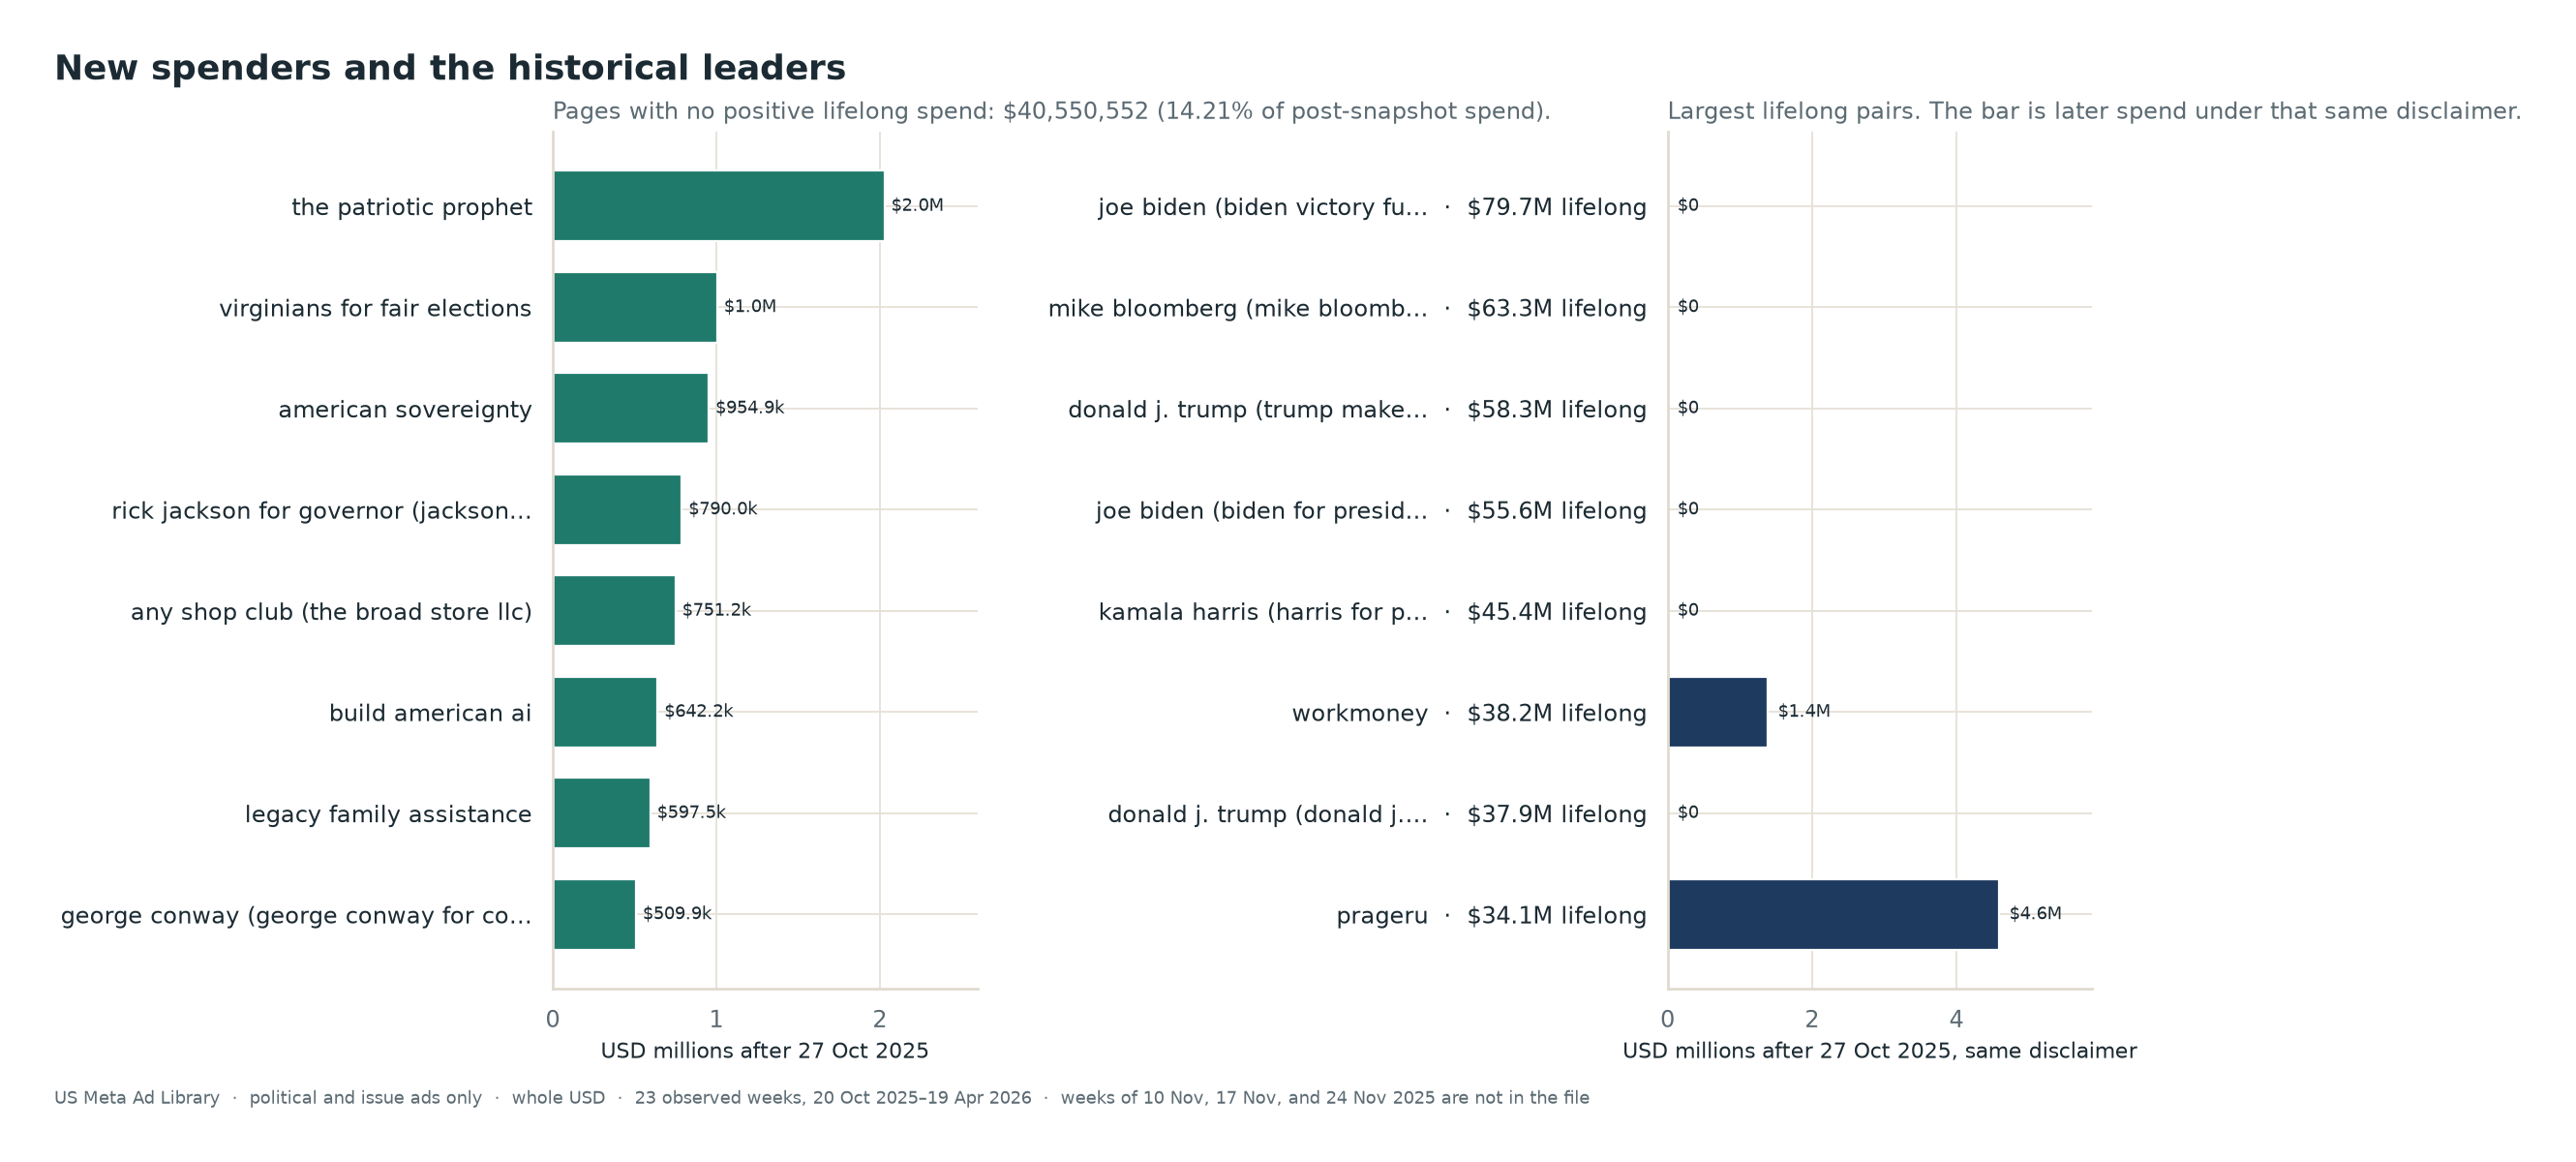

In [7]:
post = advertisers.loc[advertisers["post_snapshot_spend_usd"] > 0]
new_pages = post.loc[post["page_lifelong_spend_usd"] == 0].sort_values(
    "post_snapshot_spend_usd", ascending=False
)
new_disclaimer = post.loc[
    (post["lifelong_spend_usd"] == 0) & (post["page_lifelong_spend_usd"] > 0)
]
post_total = cov("post_snapshot_spend")
print("New pages", f"{len(new_pages):,}", usd(int(new_pages["post_snapshot_spend_usd"].sum())), rate_pct(int(new_pages["post_snapshot_spend_usd"].sum()), post_total))
print(
    "New disclaimer on an old page",
    f"{len(new_disclaimer):,}",
    usd(int(new_disclaimer["post_snapshot_spend_usd"].sum())),
)
print(
    "Lifelong dollars on pairs with no later positive spend",
    usd(cov("lifelong_spend_with_no_post_activity")),
    rate_pct(cov("lifelong_spend_with_no_post_activity"), cov("advertiser_spend_lifelong")),
)
show_new = new_pages.head(5).copy()
show_new["advertiser"] = [label(row) for row in show_new.itertuples()]
show_new["later"] = show_new["post_snapshot_spend_usd"].map(usd)
display(show_new[["advertiser", "later"]])
life = lifelong.copy()
life["lifelong"] = life["lifelong_spend_usd"].map(usd)
life["later"] = life["post_snapshot_spend_usd"].map(usd)
life["page_later"] = life["page_post_snapshot_spend_usd"].map(usd)
life["advertiser"] = [label(row) for row in life.itertuples()]
display(life[["advertiser", "lifelong", "later", "page_later"]].head(8))
display(Image(filename=str(IMAGES / "new_vs_lifelong.png")))

## 7. Reading it as a buyer

Half the positive dollars are 161 advertisers, so the weekly export of every page is not the competitive set. Spend per ad-week is $84.95, and it is not a performance metric: the file has no clicks or conversions. California and Texas lead the dollar map at $0.86 per resident, while the District of Columbia is $3.19. The lifelong leaderboard is mostly quiet after 27 October 2025. Biden Victory Fund is $79,741,106 in the snapshot and $0 later. New pages are $40,550,552, 14.21% of post-snapshot spend. The three missing November weeks are not in any of these totals.